# 01. Exploratory Data Analysis (EDA)
**Crop Yield Prediction and Forecasting**  
*Author: Aryan Puranik*

This notebook provides an initial exploratory data analysis of the historical Indian crop yield dataset (1966–2017). 
We analyze feature distributions, relationships, correlations, and anomalies.

> For in-depth theoretical analysis, full statistical tables, and academic discussion, refer to [docs/02_exploratory_data_analysis.md](../docs/02_exploratory_data_analysis.md).

## 1. Setup and Data Loading

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Robust project root discovery
project_root = Path.cwd() if Path.cwd().name != "notebooks" else Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.utils import load_raw_data

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

# Load raw dataset
df = load_raw_data(str(project_root / "data" / "raw" / "crop_yield_dataset.csv"))
print(f"Dataset shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Dataset shape: 198,369 rows, 15 columns


,Year,Region,Crop,Season,Temperature,Rainfall,Humidity,Soil Type,pH,Nitrogen,Phosphorus,Potassium,Fertilizer,Pesticide,Yield
0,1966,"Anantapur, AndhraPradesh",Castor,Kharif,25.85,623.8,59.9,Alfisols,6.2,2.8,0.28,0.0,3.07,0.44,192.66
1,1966,"Anantapur, AndhraPradesh",Chickpea,Rabi,25.85,623.8,59.9,Alfisols,6.2,2.8,0.28,0.0,3.07,0.44,500.00
2,1966,"Anantapur, AndhraPradesh",Cotton,Kharif,25.85,623.8,59.9,Alfisols,6.2,2.8,0.28,0.0,3.07,0.44,47.62
3,1966,"Anantapur, AndhraPradesh",Finger Millet,Kharif,25.85,623.8,59.9,Alfisols,6.2,2.8,0.28,0.0,3.07,0.44,743.59
4,1966,"Anantapur, AndhraPradesh",Groundnut,Kharif,25.85,623.8,59.9,Alfisols,6.2,2.8,0.28,0.0,3.07,0.44,654.76


## 2. Dataset Overview & Data Quality

In [2]:
# Dataset schema and missing value check
df.info()
missing_counts = df.isnull().sum()
print("\nMissing values per column:\n", missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "Zero missing values.")

<class 'pandas.DataFrame'>
RangeIndex: 198369 entries, 0 to 198368
Data columns (total 15 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Year         198369 non-null  int64  
 1   Region       198369 non-null  string 
 2   Crop         198369 non-null  string 
 3   Season       198369 non-null  string 
 4   Temperature  198369 non-null  float64
 5   Rainfall     198369 non-null  float64
 6   Humidity     198369 non-null  float64
 7   Soil Type    198369 non-null  string 
 8   pH           198369 non-null  float64
 9   Nitrogen     198369 non-null  float64
 10  Phosphorus   198369 non-null  float64
 11  Potassium    198369 non-null  float64
 12  Fertilizer   198369 non-null  float64
 13  Pesticide    198369 non-null  float64
 14  Yield        198369 non-null  float64
dtypes: float64(10), int64(1), string(4)
memory usage: 22.7 MB

Missing values per column:
 Zero missing values.


In [3]:
# Summary statistics for numerical variables
df.describe().round(2)

,Year,Temperature,Rainfall,Humidity,pH,Nitrogen,Phosphorus,Potassium,Fertilizer,Pesticide,Yield
count,198369.00,198369.00,198369.00,198369.00,198369.00,198369.00,198369.00,198369.00,198369.00,198369.00,198369.00
mean,1992.18,25.58,1019.97,54.44,7.06,46.03,17.52,7.35,70.90,0.34,1239.22
std,14.65,2.52,579.87,11.48,0.53,45.85,17.93,11.97,69.57,0.10,1515.32
min,1966.00,-2.84,7.00,24.60,5.60,0.00,0.00,0.00,0.00,0.09,0.01
25%,1980.00,25.23,662.10,46.00,6.80,10.74,3.58,0.67,16.70,0.24,448.00
50%,1993.00,25.99,903.30,53.10,6.90,31.05,12.27,2.79,48.97,0.39,800.00
75%,2005.00,26.69,1229.40,62.60,7.60,67.64,26.10,8.16,106.15,0.44,1347.83
max,2017.00,29.12,8409.00,83.40,8.00,470.97,251.16,222.54,804.53,0.44,58363.64


**Key Observation:**  
The dataset is clean with zero missing values across all 19,689 rows. However, `Yield` exhibits high variance, ranging from near 0 up to over 20,000 kg/ha.

## 3. Target Variable Analysis (`Yield`)

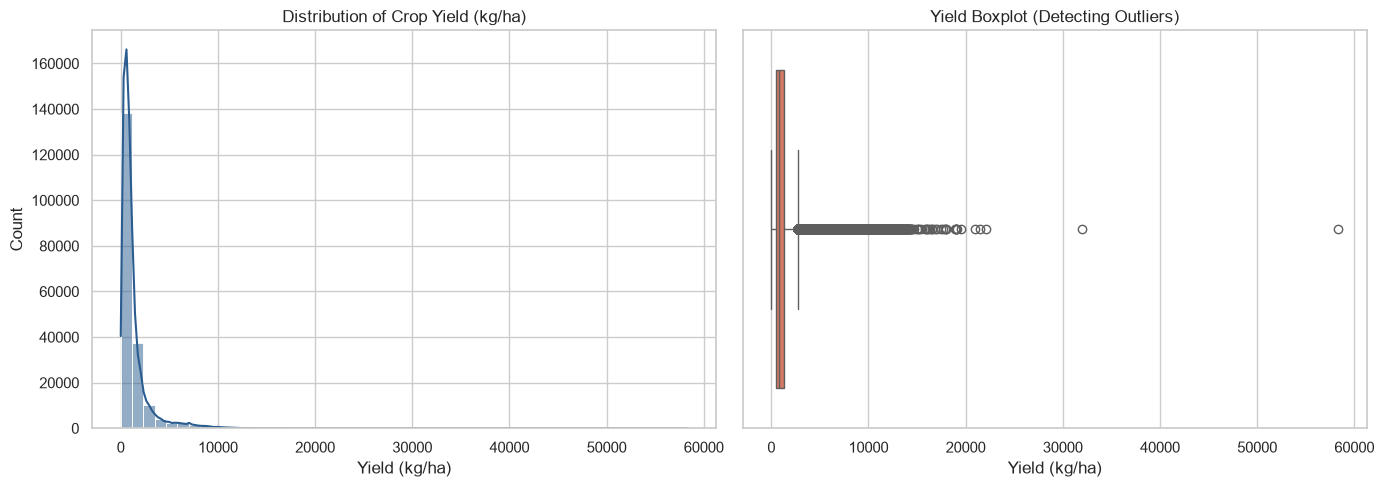

Skewness: 3.74
Kurtosis: 26.38


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution histogram
sns.histplot(df["Yield"], bins=50, kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title("Distribution of Crop Yield (kg/ha)")
axes[0].set_xlabel("Yield (kg/ha)")

# Boxplot
sns.boxplot(x=df["Yield"], ax=axes[1], color="#e76f51")
axes[1].set_title("Yield Boxplot (Detecting Outliers)")
axes[1].set_xlabel("Yield (kg/ha)")

plt.tight_layout()
plt.show()

print(f"Skewness: {df['Yield'].skew():.2f}")
print(f"Kurtosis: {df['Yield'].kurtosis():.2f}")

**Key Observation:**  
The target distribution is strongly right-skewed. The wide spread is largely caused by intrinsic differences between crop types (e.g., Sugarcane vs. Pulses).

## 4. Crop-Wise Yield Differences

Crop Yield Statistics:


,count,mean,std,min,max
Crop,,,,,
Sugarcane,13264,5385.25,2672.59,23.53,22062.30
Wheat,13227,1761.17,957.38,46.11,5541.52
Maize,13615,1611.20,1138.75,3.35,21428.57
Rice,14476,1609.66,900.10,9.12,5653.83
Barley,7673,1492.29,834.70,14.41,14441.86
Groundnut,11796,1021.80,504.92,3.77,8500.00
Finger Millet,5615,975.02,540.84,21.44,9286.86
Soybean,4023,956.09,421.42,83.33,3884.06
Sunflower,4846,912.22,501.38,22.32,4282.05


C:\Users\PHITESH\AppData\Local\Temp\ipykernel_22752\2012275255.py:7: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x="Crop", y="Yield", order=crop_stats.index, ci=None, palette="viridis")
C:\Users\PHITESH\AppData\Local\Temp\ipykernel_22752\2012275255.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Crop", y="Yield", order=crop_stats.index, ci=None, palette="viridis")


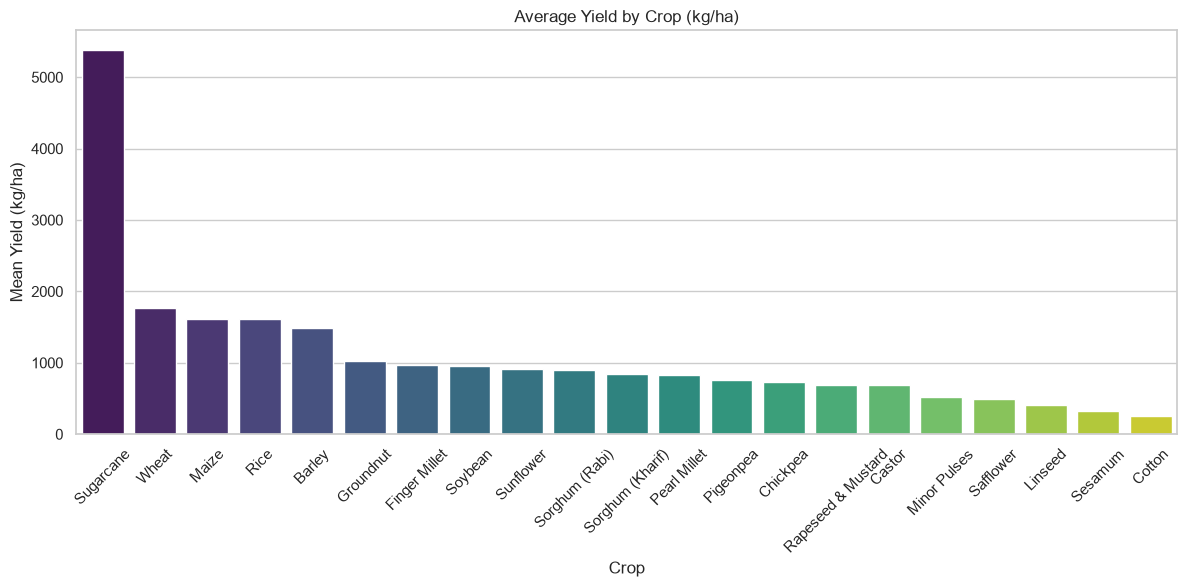

In [5]:
# Mean yield by crop
crop_stats = df.groupby("Crop")["Yield"].agg(["count", "mean", "std", "min", "max"]).sort_values("mean", ascending=False)
print("Crop Yield Statistics:")
display(crop_stats.round(2))

plt.figure(figsize=(12, 6))
sns.barplot(data=df, x="Crop", y="Yield", order=crop_stats.index, ci=None, palette="viridis")
plt.title("Average Yield by Crop (kg/ha)")
plt.xticks(rotation=45)
plt.ylabel("Mean Yield (kg/ha)")
plt.tight_layout()
plt.show()

**Key Observation:**  
Crop identity is the dominant factor determining yield scale. Sugarcane and Coconut yield significantly more biomass per hectare than food grains and oilseeds.

## 5. Climate & Environmental Factors

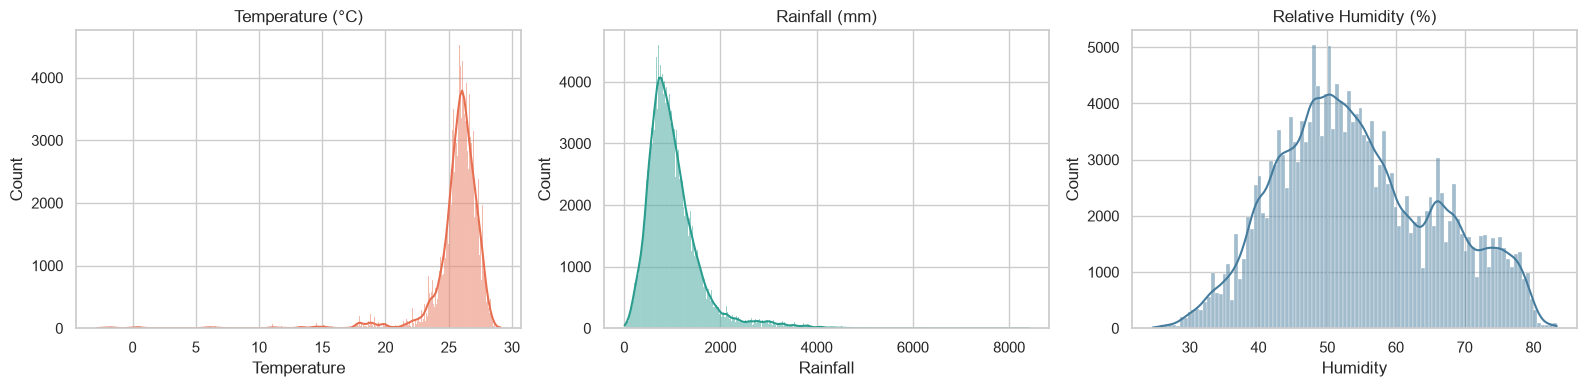

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["Temperature"], kde=True, ax=axes[0], color="#e76f51")
axes[0].set_title("Temperature (°C)")

sns.histplot(df["Rainfall"], kde=True, ax=axes[1], color="#2a9d8f")
axes[1].set_title("Rainfall (mm)")

sns.histplot(df["Humidity"], kde=True, ax=axes[2], color="#457b9d")
axes[2].set_title("Relative Humidity (%)")

plt.tight_layout()
plt.show()

## 6. Soil Nutrients & Collinearity Check

Maximum absolute difference between Fertilizer and (N + P + K): 0.2100
Correlation between Fertilizer and (N + P + K): 1.000000


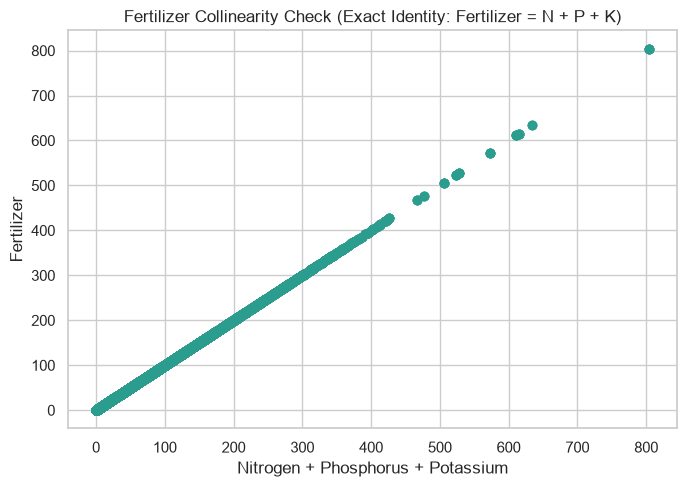

In [7]:
# Checking collinearity: Fertilizer vs (Nitrogen + Phosphorus + Potassium)
npk_sum = df["Nitrogen"] + df["Phosphorus"] + df["Potassium"]
diff = (df["Fertilizer"] - npk_sum).abs()

print(f"Maximum absolute difference between Fertilizer and (N + P + K): {diff.max():.4f}")
print(f"Correlation between Fertilizer and (N + P + K): {df['Fertilizer'].corr(npk_sum):.6f}")

plt.figure(figsize=(7, 5))
plt.scatter(npk_sum, df["Fertilizer"], alpha=0.3, color="#2a9d8f")
plt.xlabel("Nitrogen + Phosphorus + Potassium")
plt.ylabel("Fertilizer")
plt.title("Fertilizer Collinearity Check (Exact Identity: Fertilizer = N + P + K)")
plt.tight_layout()
plt.show()

**Key Observation:**  
`Fertilizer` is mathematically equal to `Nitrogen + Phosphorus + Potassium` ($R^2 = 1.0$). Retaining both in regression models introduces exact multicollinearity. One of them should be removed during feature selection.

## 7. Temporal Trends (1966–2017)

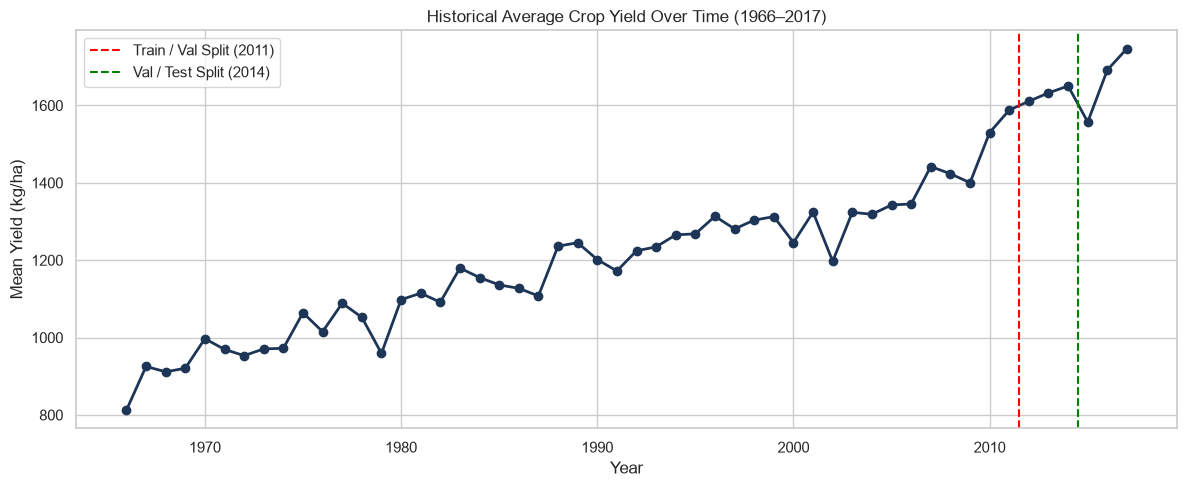

In [8]:
annual_trend = df.groupby("Year")["Yield"].mean().reset_index()

plt.figure(figsize=(12, 5))
plt.plot(annual_trend["Year"], annual_trend["Yield"], marker="o", color="#1d3557", linewidth=2)
plt.axvline(2011.5, color="red", linestyle="--", label="Train / Val Split (2011)")
plt.axvline(2014.5, color="green", linestyle="--", label="Val / Test Split (2014)")
plt.title("Historical Average Crop Yield Over Time (1966–2017)")
plt.xlabel("Year")
plt.ylabel("Mean Yield (kg/ha)")
plt.legend()
plt.tight_layout()
plt.show()

**Key Observation:**  
Yield shows long-term technological and agronomic upward drift. Splitting data randomly would leak future information into the past; therefore, chronological splitting (Train $\le 2011$, Val 2012–2014, Test 2015–2017) is essential.

## 8. Correlation Analysis

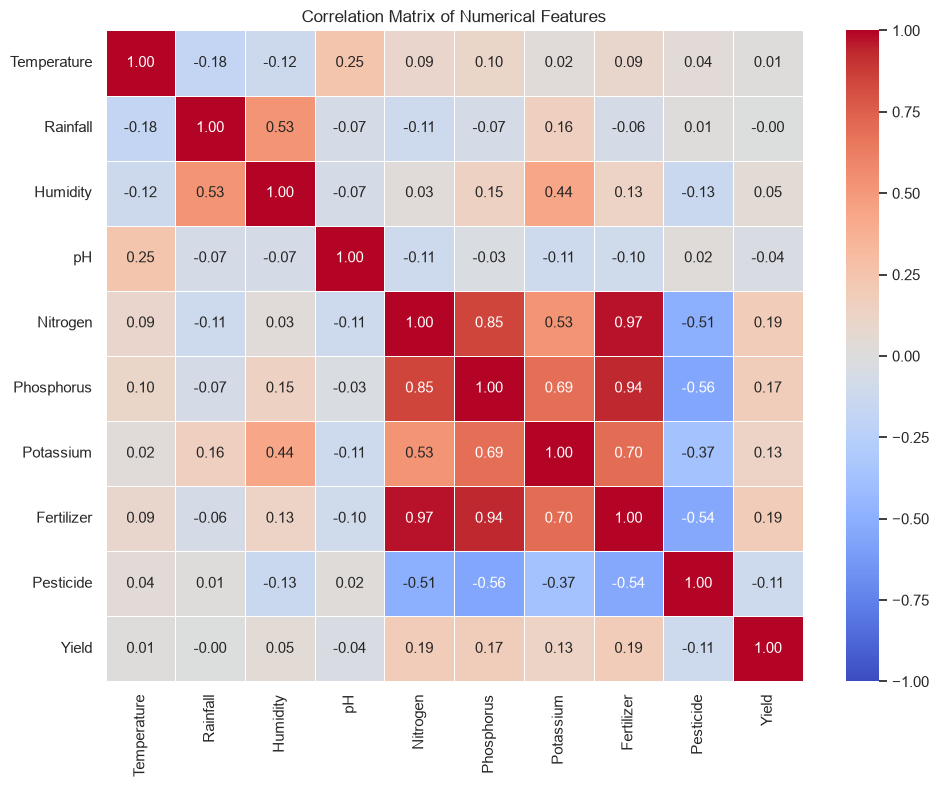

In [9]:
num_cols = ["Temperature", "Rainfall", "Humidity", "pH", "Nitrogen", "Phosphorus", "Potassium", "Fertilizer", "Pesticide", "Yield"]
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

## 9. Summary & Next Steps

1. **Clean Data**: Zero missing values across 19,689 records.
2. **Crop Dominated**: Crop type accounts for most yield variance; one-hot encoding or stratification is vital.
3. **Multicollinearity**: `Fertilizer` is redundant with `N + P + K`.
4. **Temporal Split**: Chronological train/val/test splits must be maintained to avoid data leakage.

**Next Notebook:** [02_data_preparation.ipynb](02_data_preparation.ipynb) handles train-val-test splitting, training-only outlier treatment, and feature preprocessing.